# 04. Статистика без асимптотики и без меток

Три вопроса, углубляющие анализ из `02_analysis.ipynb`:

1. Подтверждают ли перестановочный тест и бутстреп выводы t-критерия Уэлча без опоры на ЦПТ и формулу для степеней свободы?
2. Как формально учесть конфаундер в парадоксе Симпсона - через линейную регрессию.
3. Можно ли найти виды без меток, только по форме облаков точек - смесью гауссовских распределений.

In [3]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.metrics import adjusted_rand_score  # сходство двух разбиений на группы
from sklearn.mixture import GaussianMixture  # смесь гауссиан, обучаемая EM-алгоритмом
from sklearn.preprocessing import StandardScaler

from palmer_penguins.data import PROJECT_ROOT, load_clean

# перестановочный тест, бутстреп и метод наименьших квадратов
from palmer_penguins.inference import bootstrap_ci, ols, permutation_test

FIG = PROJECT_ROOT / "reports" / "figures"
df = load_clean()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Перестановочный тест и бутстреп

**Перестановочный тест.** Гипотеза $H_0$: массы самцов и самок распределены одинаково. Тогда метка "самец/самка" ничего не значит, и её можно переставить между птицами - распределение данных не изменится. Перемешиваем метки $B$ раз, каждый раз считаем разность средних $d^{(b)}$ и смотрим, как часто она не меньше наблюдаемой по модулю.

$$
\hat p = \frac{1 + \#\{b : |d^{(b)}| \geq |d_{\text{набл}}|\}}{1 + B}.
$$

Единицы в числителе и знаменателе учитывают саму наблюдаемую раскладку как одну из возможных перестановок, поэтому $\hat p$ никогда не равно нулю.

**Бутстреп.** Неизвестное распределение каждой группы заменяем эмпирическим: выбираем из группы $n$ значений с возвращением, пересчитываем разность средних и так $B$ раз. Квантили $2.5\%$ и $97.5\%$ полученных разностей дают 95%-доверительный интервал.

Ни один из методов не требует нормальности или больших выборок.

In [ ]:
# Те же группы, что в вопросе 2 блокнота 02, то есть самцы и самки Adelie с известным полом.
adelie = df[df["species"] == "Adelie"].dropna(subset=["sex"])
males = adelie.loc[adelie["sex"] == "male", "body_mass_g"]
females = adelie.loc[adelie["sex"] == "female", "body_mass_g"]

# Перестановочный тест: наблюдаемая разность, p-значение
# и 9999 разностей «при H0» — они понадобятся для гистограммы.
observed, p_perm, null_diffs = permutation_test(males, females)

# Бутстреп-интервал для разности средних.
boot_low, boot_high = bootstrap_ci(males, females)

# Для сравнения - классический t-критерий Уэлча.
welch = stats.ttest_ind(males, females, equal_var=False)
welch_ci = welch.confidence_interval(0.95)

# Сводная таблица.
pd.DataFrame(
    {
        "p-значение": [welch.pvalue, p_perm],
        "интервал: от": [welch_ci.low, boot_low],
        "интервал: до": [welch_ci.high, boot_high],
    },
    index=["Уэлч", "перестановки / бутстреп"],
)

,p-значение,интервал: от,интервал: до
Уэлч,6.402320e-26,573.013906,776.301162
перестановки / бутстреп,1.000000e-04,577.037671,775.684932


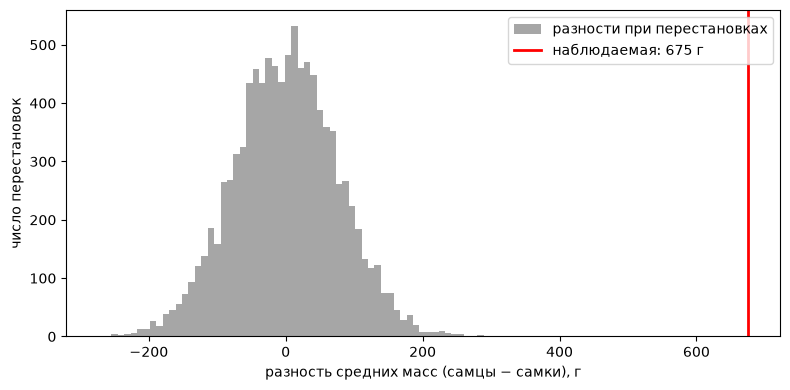

In [5]:
# Как выглядит распределение разности средних, если H0 верна,
# и где на его фоне находится наблюдаемая разность.
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(
    null_diffs, bins=60, color="gray", alpha=0.7, label="разности при перестановках"
)
ax.axvline(observed, color="red", linewidth=2, label=f"наблюдаемая: {observed:.0f} г")
ax.set_xlabel("разность средних масс (самцы − самки), г")
ax.set_ylabel("число перестановок")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "permutation_test.png", dpi=120)

Наблюдаемая разность (≈675 г) далеко за пределами всего, что дают перестановки, все 9999 разностей лежат в пределах ±300 г, а 95% из них - в пределах ±150 г. Ни одна из 9999 перестановок не дала разности не меньше наблюдаемой, поэтому $\hat p = 1/10000 = 0.0001$.

Это предел разрешения метода. При $B$ перестановках p-значение не может быть меньше $1/(B+1)$. Уэлч даёт $p \approx 6 \cdot 10^{-26}$ - это не более точный ответ, а экстраполяция по хвосту теоретического распределения. Вывод одинаковый: разница не случайна.

Интервалы почти совпадают: бутстреп $\approx [577;\ 776]$ г, Уэлч $\approx [573;\ 776]$ г.

Проверим методы на случае, где разницы, скорее всего, нет - масса Chinstrap и Adelie (средние ≈3733 и ≈3701 г).

In [ ]:
chinstrap = df.loc[df["species"] == "Chinstrap", "body_mass_g"]
adelie_all = df.loc[df["species"] == "Adelie", "body_mass_g"]

observed2, p_perm2, _ = permutation_test(chinstrap, adelie_all)
boot_low2, boot_high2 = bootstrap_ci(chinstrap, adelie_all)
welch2 = stats.ttest_ind(chinstrap, adelie_all, equal_var=False)
welch_ci2 = welch2.confidence_interval(0.95)

print(f"разность средних: {observed2:.0f} г")
print(
    f"Уэлч:         p = {welch2.pvalue:.3f}, интервал [{welch_ci2.low:.0f}; {welch_ci2.high:.0f}]"
)
print(f"перестановки: p = {p_perm2:.3f}, бутстреп [{boot_low2:.0f}; {boot_high2:.0f}]")

разность средних: 32 г
Уэлч:         p = 0.588, интервал [-86; 150]
перестановки: p = 0.605, бутстреп [-86; 149]


Здесь оба подхода дают пхожие результаты: $p \approx 0.6$, интервалы $\approx [-86;\ 150]$ г содержат ноль - различия в массе между Chinstrap и Adelie данные не показывают.

**Вывод 1.** На наших данных классический t-критерий и методы без предположений о распределении дают одинаковые выводы. Ожидаемо, так как выборки по 68–152 птицы, и ЦПТ работает хорошо. На маленьких или сильно скошенных выборках перестановки и бутстреп надёжнее.

## 2. Парадокс Симпсона через регрессию

Модель линейной регрессии у нас - глубина клюва = линейная функция признаков + шум,

$$
y_i = \beta_0 + \beta_1 x_{i1} + \dots + \beta_p x_{ip} + \varepsilon_i .
$$

Метод наименьших квадратов ищет $\beta$, минимизирующее $\|y - A\beta\|^2$, где $A$ - матрица признаков со столбцом единиц. Решение $\hat\beta = (A^\top A)^{-1} A^\top y$. Стандартные ошибки - корни диагонали матрицы $\hat\sigma^2 (A^\top A)^{-1}$, где $\hat\sigma^2$ сумма квадратов остатков, делённая на $n - k$.

Сравним две модели: с одной длиной клюва и с длиной плюс вид.

In [9]:
# Модель 1: глубина ~ длина. Двойные скобки — таблица из одного столбца.
ols(df[["bill_length_mm"]], df["bill_depth_mm"]).round(3)

,coef,se,low,high
intercept,20.885,0.844,19.226,22.545
bill_length_mm,-0.085,0.019,-0.123,-0.048


In [10]:
# Модель 2: глубина ~ длина + вид.
species_dummies = pd.get_dummies(df["species"], drop_first=True, dtype=float)

# Склеиваем признаки по столбцам (axis=1).
X_with_species = pd.concat([df[["bill_length_mm"]], species_dummies], axis=1)
ols(X_with_species, df["bill_depth_mm"]).round(3)

,coef,se,low,high
intercept,10.592,0.683,9.249,11.936
bill_length_mm,0.200,0.017,0.165,0.234
Chinstrap,-1.933,0.224,-2.374,-1.492
Gentoo,-5.106,0.191,-5.483,-4.729


**Коэффициент при длине клюва сменил знак:**
- без учёта вида: $\hat\beta_1 \approx -0.085$, 95%-интервал $[-0.123;\ -0.048]$;
- с учётом вида: $\hat\beta_1 \approx +0.200$, интервал $[0.165;\ 0.234]$.

Оба интервала не содержат ноль, так что смена знака не шум. Во второй модели коэффициент означает, что при одном и том же виде клюв длиннее на 1 мм в среднем глубже на 0.2 мм. Коэффициенты видов - сдвиги относительно Adelie при одинаковой длине клюва. У Chinstrap клюв мельче на ≈1.9 мм, у Gentoo на ≈5.1 мм.

**Вывод 2.** Добавление вида в модель - формальный способ учесть конфаундер. Он даёт ту же картину, что корреляции по видам в `02_analysis`, но одним числом с доверительным интервалом.

## 3. Смесь гауссиан: виды без меток

Спрячем виды и спросим, видно ли три группы по одной лишь форме данных? Модель - смесь $K$ нормальных распределений

$$
p(x) = \sum_{k=1}^{K} \pi_k\, \mathcal{N}(x \mid \mu_k, \Sigma_k), \qquad \pi_k \geq 0,\ \ \sum_k \pi_k = 1 .
$$

Параметры находит **EM-алгоритм**, чередуя два шага:
- **E-шаг:** для каждой точки - вероятность принадлежности каждой компоненте, $\gamma_{ik} = \dfrac{\pi_k \mathcal{N}(x_i \mid \mu_k, \Sigma_k)}{\sum_j \pi_j \mathcal{N}(x_i \mid \mu_j, \Sigma_j)}$;
- **M-шаг:** пересчёт $\pi_k, \mu_k, \Sigma_k$ как взвешенных с весами $\gamma_{ik}$ долей, средних и ковариаций.

Каждая итерация не уменьшает правдоподобие, но гарантирует сходимость только к локальному максимуму.

Сколько компонент? Выбираем $K$ по критерию BIC — правдоподобие со штрафом за число параметров $m$:

$$
\mathrm{BIC} = -2 \ln \hat L + m \ln n \quad \to \min .
$$

In [ ]:
features = ["bill_length_mm", "bill_depth_mm"]
X = df[features].to_numpy()  # матрица 342 × 2 без названий столбцов

scaler = StandardScaler().fit(X)
X_std = scaler.transform(X)

# BIC для K = 1..6.
# covariance_type="full" — у каждой компоненты своя произвольная матрица ковариаций;
# n_init=10 — 10 запусков EM с разных начальных
# точек, берётся лучший по правдоподобию.
bic = {}
for k in range(1, 7):
    gmm = GaussianMixture(k, covariance_type="full", n_init=10, random_state=42)
    gmm.fit(X_std)
    bic[k] = gmm.bic(X_std)

pd.Series(bic, name="BIC").round(1)

1    1950.8
2    1795.5
3    1743.5
4    1767.4
5    1795.4
6    1814.9
Name: BIC, dtype: float64

Минимум BIC при $K = 3$. По одной только форме облаков можно сделать вывод, что групп три. Дальше смотрим, совпадают ли эти три группы с видами.

Мера совпадения - скорректированный индекс Рэнда (ARI). Индекс Рэнда - доля пар точек, по которым два разбиения согласны (обе точки в одной группе или обе в разных). Скорректированная версия вычитает ожидаемое при случайном разбиении значение, то есть если $\mathrm{ARI} = 1$, то разбиения совпадают, а при $\approx 0$ согласие не лучше случайного.

In [14]:
gmm = GaussianMixture(3, covariance_type="full", n_init=10, random_state=42)
gmm.fit(X_std)
clusters = gmm.predict(X_std)

print(f"ARI: {adjusted_rand_score(df['species'], clusters):.3f}")

pd.crosstab(df["species"], clusters, colnames=["кластер"])

ARI: 0.912


кластер,0,1,2
species,,,
Adelie,0,150,1
Chinstrap,2,6,60
Gentoo,120,0,3


Зачем понадобилаь стандартизация. Для смеси с полными ковариациями это, казалось бы, не нужно, ведь модель инвариантна к растяжению осей - эллипсы просто растянутся вместе с данными. Сравним два обучения: на исходных данных и на стандартизированных.

Чтобы сравнить правдоподобия, переведём их в одни единицы. При замене $z_j = (x_j - m_j)/s_j$ плотности связаны якобианом $\ln p_X(x) = \ln p_Z(z) - \sum_j \ln s_j$.

In [15]:
gmm_raw = GaussianMixture(3, covariance_type="full", n_init=10, random_state=42)
gmm_raw.fit(X)  # те же настройки, но на исходных данных в миллиметрах

# score() — среднее логарифмическое правдоподобие на одну точку.
# Для стандартизированной модели переводим его в единицы исходных данных.
log_jacobian = np.sum(np.log(scaler.scale_))
loglik_raw = gmm_raw.score(X)
loglik_std = gmm.score(X_std) - log_jacobian

pd.DataFrame(
    {
        "ср. лог-правдоподобие": [loglik_raw, loglik_std],
        "ARI с видами": [
            adjusted_rand_score(df["species"], gmm_raw.predict(X)),
            adjusted_rand_score(df["species"], clusters),
        ],
    },
    index=["исходные данные", "стандартизированные"],
).round(4)

,ср. лог-правдоподобие,ARI с видами
исходные данные,-4.7980,0.8314
стандартизированные,-4.7788,0.9118


На исходных данных EM сошёлся к худшему локальному максимуму, правдоподобие ниже, и с видами кластеры совпадают хуже (ARI ≈0.83 против ≈0.91). Причина в инициализации. По умолчанию начальные центры выбирает алгоритм k-средних, а он работает с евклидовыми расстояниями и потому чувствителен к масштабу осей. После стандартизации старт лучше, и EM находит более высокий максимум.

Посмотрим на картинку: слева настоящие виды, справа - найденные кластеры.

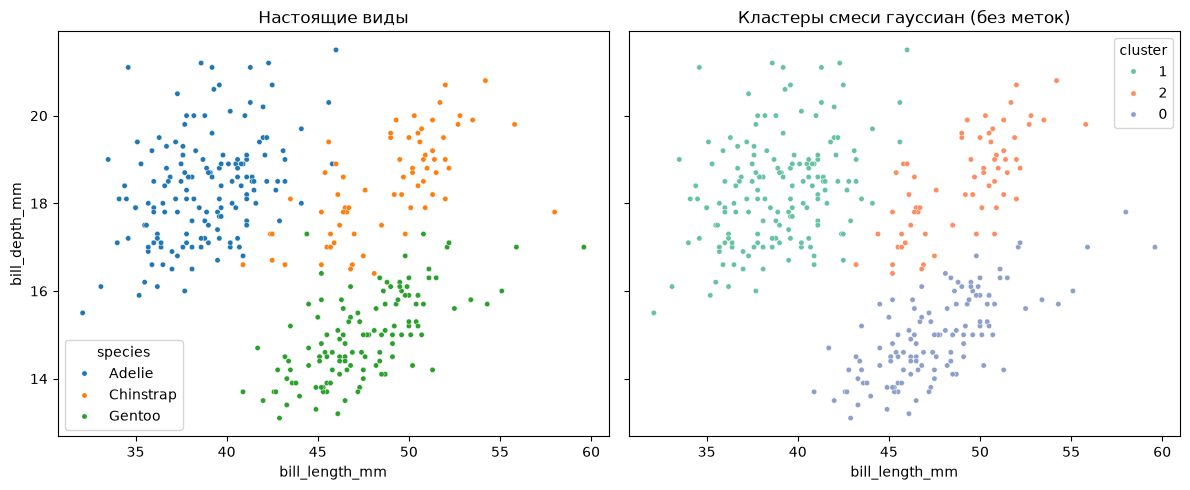

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

# Слева — настоящие виды.
sns.scatterplot(
    data=df, x="bill_length_mm", y="bill_depth_mm", hue="species", s=15, ax=axes[0]
)
axes[0].set_title("Настоящие виды")

sns.scatterplot(
    data=df.assign(cluster=clusters.astype(str)),
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="cluster",
    palette="Set2",
    s=15,
    ax=axes[1],
)
axes[1].set_title("Кластеры смеси гауссиан (без меток)")

fig.tight_layout()
fig.savefig(FIG / "gmm_clusters.png", dpi=120)

**Вывод 3.** Не зная видов, по двум размерам клюва смесь гауссиан находит три группы (BIC выбирает $K = 3$), и они в основном совпадают с видами (ARI ≈0.91). Расхождения в зонах перекрытия облаков, там же, где ошибались и классификаторы в `03_models`.

## Итоги

1. Перестановочный тест и бутстреп подтверждают выводы Уэлча: самцы Adelie тяжелее самок на ≈675 г, а масса Chinstrap и Adelie не различается.
2. В регрессии с учётом вида коэффициент при длине клюва меняет знак: $-0.085 \to +0.200$, оба интервала не содержат ноль.
3. Без меток смесь гауссиан находит три группы, близкие к видам. EM сходится к локальным максимумам, и стандартизация признаков помогла ему найти лучший.